In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test = pd.read_csv("data/clean/test_scored.csv")

# Illustrative assumptions for an unsecured personal loan
loan_amount = 5000
profit_per_good = 400              # interest earned minus costs, if they repay
lgd = 0.60                         # Loss Given Default: share of the loan never recovered
loss_per_bad = loan_amount * lgd   # £3,000 lost per defaulter

print("Break-even bad rate:", round(profit_per_good / (profit_per_good + loss_per_bad) * 100, 1), "%")

Break-even bad rate: 11.8 %


In [2]:
rows = []
for c in range(int(test["score"].min()), int(test["score"].max()) + 1):
    approved = test[test["score"] >= c]
    bads = approved["default_2yrs"].sum()
    goods = len(approved) - bads
    rows.append({
        "cutoff": c,
        "approval_rate": round(len(approved) / len(test) * 100, 1),
        "bad_rate": round(bads / max(len(approved), 1) * 100, 2),
        "profit": goods * profit_per_good - bads * loss_per_bad})

results = pd.DataFrame(rows)
results["profit_per_10k_apps"] = (results["profit"] / len(test) * 10000).round(0)

best = results.loc[results["profit"].idxmax()]
everyone = results.iloc[0]
print("Approve everyone:  profit per 10k applicants £", f"{everyone['profit_per_10k_apps']:,.0f}")
print("Best cut-off:", int(best["cutoff"]),
      "| approval", best["approval_rate"], "%",
      "| bad rate", best["bad_rate"], "%",
      "| profit per 10k £", f"{best['profit_per_10k_apps']:,.0f}")

Approve everyone:  profit per 10k applicants £ 1,727,289
Best cut-off: 548 | approval 87.1 % | bad rate 3.0 % | profit per 10k £ 2,595,022


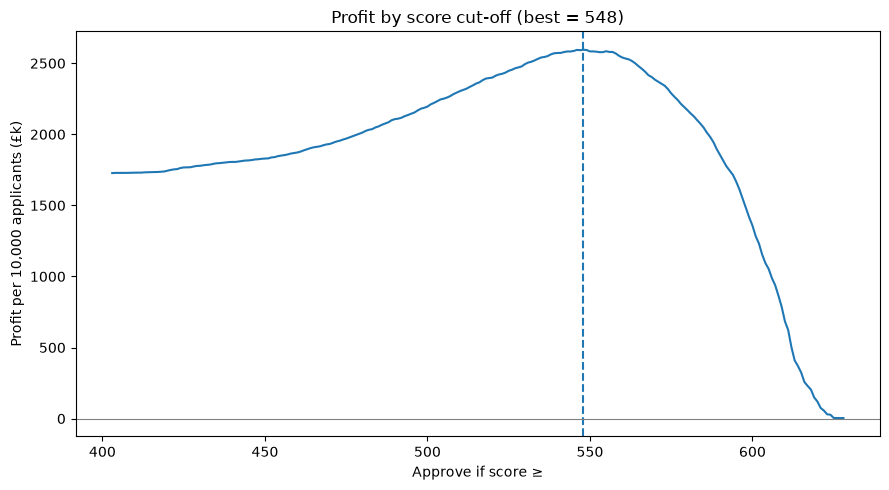

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(results["cutoff"], results["profit_per_10k_apps"] / 1000)
plt.axvline(best["cutoff"], linestyle="--")
plt.axhline(0, color="grey", linewidth=0.8)
plt.title(f"Profit by score cut-off (best = {int(best['cutoff'])})")
plt.xlabel("Approve if score ≥")
plt.ylabel("Profit per 10,000 applicants (£k)")
plt.tight_layout()
import os
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/profit_curve.png", dpi=150)
plt.show()

In [4]:
sens = []
for lgd_test in [0.4, 0.6, 0.8]:
    loss = loan_amount * lgd_test
    p = [( (len(a := test[test["score"] >= c]) - a["default_2yrs"].sum()) * profit_per_good
           - a["default_2yrs"].sum() * loss, c)
         for c in range(int(test["score"].min()), int(test["score"].max()) + 1)]
    top_profit, top_cut = max(p)
    sens.append({"LGD": lgd_test, "loss_per_bad": loss, "best_cutoff": top_cut,
                 "approval_rate": round((test["score"] >= top_cut).mean() * 100, 1)})
pd.DataFrame(sens)

,LGD,loss_per_bad,best_cutoff,approval_rate
0,0.4,2000.0,539,89.9
1,0.6,3000.0,548,87.1
2,0.8,4000.0,557,80.9


In [5]:
results.to_csv("outputs/cutoff_results.csv", index=False)